In [17]:

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler

import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('Iris.csv')
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [19]:
x = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
x

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [20]:
x = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
std_scaler = StandardScaler()
x_scaled = std_scaler.fit_transform(x)
x = pd.DataFrame(x_scaled,columns=x.columns)
x

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977
...,...,...,...,...
145,1.038005,-0.124958,0.819624,1.447956
146,0.553333,-1.281972,0.705893,0.922064
147,0.795669,-0.124958,0.819624,1.053537
148,0.432165,0.800654,0.933356,1.447956


In [21]:
kmeans_model = KMeans(n_clusters=2)
kmeans_model.fit(x)
y_pred = kmeans_model.fit_predict(x)
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [22]:
np.where(y_pred == 1)[0].shape

(50,)

In [23]:
np.where(y_pred == 0)[0].shape

(100,)

In [24]:
kmeans_model = KMeans(n_clusters=3)
kmeans_model.fit(x)
y_pred = kmeans_model.fit_predict(x)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 1,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1], dtype=int32)

In [25]:
np.where(y_pred == 0)[0].shape

(49,)

In [26]:
np.where(y_pred == 1)[0].shape

(55,)

In [27]:
np.where(y_pred == 2)[0].shape

(46,)

In [28]:
wcss_list = []
k_values = range(1,7)
for i in k_values:

    kmeans_model = KMeans(n_clusters=i)
    kmeans_model.fit(x)
    wcss = np.around(kmeans_model.inertia_,4)
    wcss_list.append(wcss)
    print(i,">>",wcss)


1 >> 600.0
2 >> 223.732
3 >> 141.1542
4 >> 115.6807
5 >> 91.5748
6 >> 85.4114


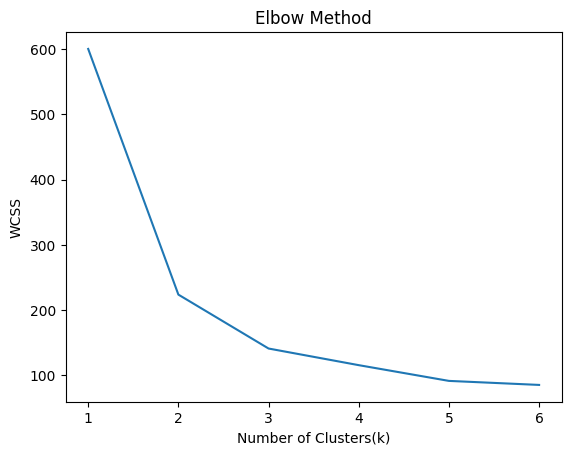

In [29]:
plt.plot(k_values,wcss_list)
plt.xlabel("Number of Clusters(k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.savefig("Elbow_Method.png")

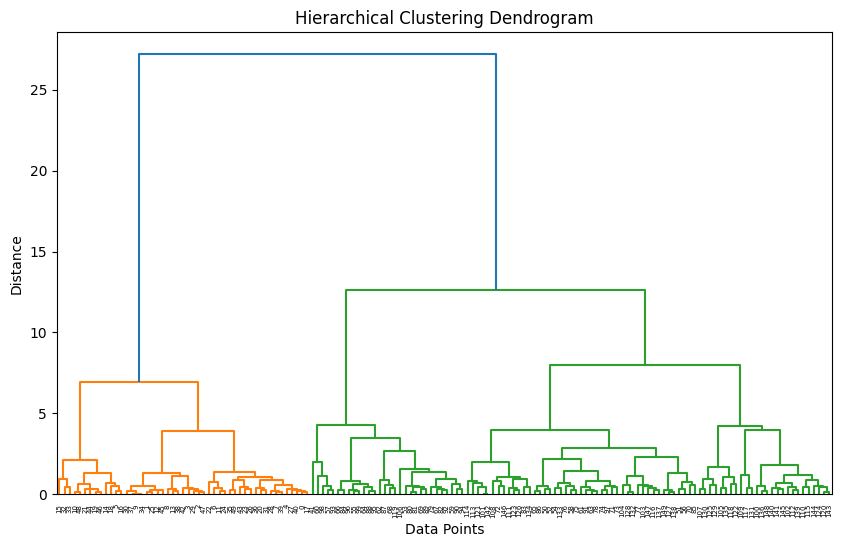

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  Cluster
0      -0.900681      1.032057      -1.341272     -1.312977        1
1      -1.143017     -0.124958      -1.341272     -1.312977        1
2      -1.385353      0.337848      -1.398138     -1.312977        1
3      -1.506521      0.106445      -1.284407     -1.312977        1
4      -1.021849      1.263460      -1.341272     -1.312977        1


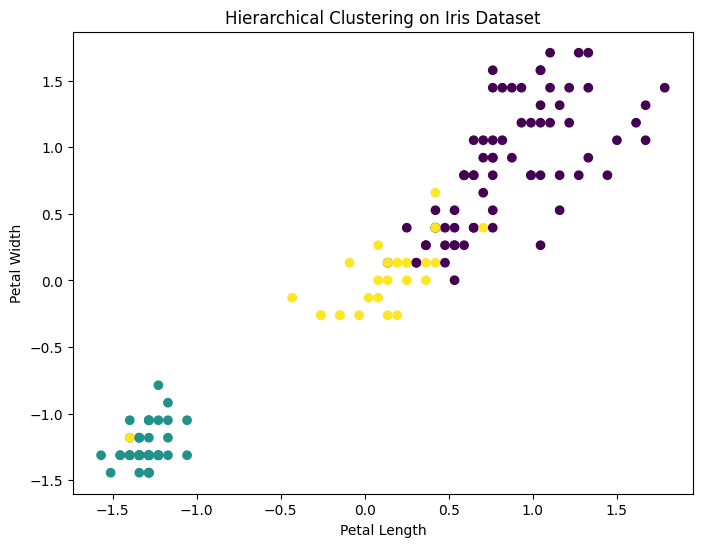

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Convert to DataFrame
iris_df = pd.DataFrame(x_scaled,columns=x.columns)


# Dendrogram
linked = linkage(x_scaled, method='ward')

plt.figure(figsize=(10, 6))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# Hierarchical clustering
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

clusters = hc.fit_predict(x_scaled)

# Add cluster labels
iris_df['Cluster'] = clusters

print(iris_df.head())

# Visualization
plt.figure(figsize=(8, 6))

plt.scatter(
   x_scaled[:, 2],
   x_scaled[:, 3],
   c=clusters
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Hierarchical Clustering on Iris Dataset")

plt.show()